# ___Haberman_Data_Analysis___

## _Dataset Detail_

**Title :-** `Haberman's Survival Data`

**Sources :-**

* **Donor :-** Tjen-Sien Lim (<limt@stat.wisc.edu>)

* **Date :-** $March$ $4, 1999$

**Past Usage :-**

* Haberman, S. J. ($1976$). Generalized Residuals for Log-Linear
Models, Proceedings of the $9th$ International Biometrics
Conference, Boston, pp. $104-122$.
 
* Landwehr, J. M., Pregibon, D., and Shoemaker, A. C. ($1984$),
Graphical Models for Assessing Logistic Regression Models (with
discussion), Journal of the American Statistical Association $79:
61-83$.

* Lo, W.-D. ($1993$). Logistic Regression Trees, PhD thesis,
Department of Statistics, University of Wisconsin, Madison, WI.

**Relevant Information :-** The dataset contains cases from a study that was conducted between
$1958$ and $1970$ at the `University of Chicago's` Billings Hospital on
the survival of patients who had undergone surgery for breast
cancer.

**Number of Instances :-** $306$

**Number of Attributes :-** $4$ (including the class attribute)

**Attribute Information :-**

* Age of patient at time of operation ($numerical$)
* Patient's year of operation (year - $1900$, $numerical$)
* Number of positive axillary nodes detected ($numerical$)
* Survival status (class attribute)
	* $1$ = the patient survived $5$ years or longer
	* $2$ = the patient died within $5$ year

**Missing Attribute Values :-** $None$





## *Dataset Configuration*

In [106]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sbn
import plotly.express as px

In [107]:
haberman = pd.read_csv("Haberman.csv")

In [108]:
haberman.columns = ["age", "operation_year", "axil_nodes", "survival_status"]

In [109]:
haberman

,age,operation_year,axil_nodes,survival_status
0,30,62,3,1
1,30,65,0,1
2,31,59,2,1
3,31,65,4,1
4,33,58,10,1
...,...,...,...,...
300,75,62,1,1
301,76,67,0,1
302,77,65,3,1
303,78,65,1,2


## _High level statistics of the dataset_

In [110]:
haberman.describe()

,age,operation_year,axil_nodes,survival_status
count,305.000000,305.000000,305.000000,305.000000
mean,52.531148,62.849180,4.036066,1.265574
std,10.744024,3.254078,7.199370,0.442364
min,30.000000,58.000000,0.000000,1.000000
25%,44.000000,60.000000,0.000000,1.000000
50%,52.000000,63.000000,1.000000,1.000000
75%,61.000000,66.000000,4.000000,2.000000
max,83.000000,69.000000,52.000000,2.000000


In [111]:
haberman.head()

,age,operation_year,axil_nodes,survival_status
0,30,62,3,1
1,30,65,0,1
2,31,59,2,1
3,31,65,4,1
4,33,58,10,1


In [112]:
df = haberman.sample(frac=0.10).head()
df

,age,operation_year,axil_nodes,survival_status
190,56,66,3,2
33,39,66,0,2
43,41,64,0,2
117,49,66,0,1
303,78,65,1,2


In [113]:
hm = haberman.sample(n=10).head()
hm

,age,operation_year,axil_nodes,survival_status
183,55,58,1,1
156,53,65,1,2
114,49,64,10,2
147,52,69,0,1
41,40,65,0,1


## _Numbers of points_

In [114]:
haberman.shape

(305, 4)

In [115]:
haberman.value_counts()

age  operation_year  axil_nodes  survival_status
61   59              0           1                  3
37   63              0           1                  2
48   58              11          2                  2
55   58              1           1                  2
65   64              0           1                  2
                                                   ..
48   67              7           2                  1
49   60              1           1                  1
     61              0           1                  1
                     1           1                  1
83   58              2           2                  1
Length: 288, dtype: int64

In [116]:
haberman["age"].value_counts()

52    14
54    13
50    12
57    11
53    11
47    11
43    11
55    10
41    10
65    10
49    10
38    10
42     9
45     9
61     9
63     8
59     8
56     7
62     7
58     7
34     7
70     7
48     7
46     7
44     7
37     6
51     6
60     6
39     6
67     6
64     5
66     5
72     4
69     4
40     3
73     2
74     2
30     2
68     2
31     2
36     2
35     2
33     2
71     1
75     1
76     1
77     1
78     1
83     1
Name: age, dtype: int64

In [117]:
haberman["operation_year"].value_counts()

58    36
64    30
63    30
65    28
60    28
66    28
59    27
61    26
67    25
62    23
68    13
69    11
Name: operation_year, dtype: int64

In [118]:
haberman["axil_nodes"].value_counts()

0     136
1      40
3      20
2      20
4      13
7       7
6       7
8       7
9       6
5       6
13      5
14      4
11      4
22      3
19      3
23      3
15      3
10      3
20      2
12      2
21      1
52      1
30      1
16      1
24      1
46      1
18      1
35      1
17      1
25      1
28      1
Name: axil_nodes, dtype: int64

In [119]:
haberman["survival_status"].value_counts()

1    224
2     81
Name: survival_status, dtype: int64

In [120]:
haberman.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 305 entries, 0 to 304
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   age              305 non-null    int64
 1   operation_year   305 non-null    int64
 2   axil_nodes       305 non-null    int64
 3   survival_status  305 non-null    int64
dtypes: int64(4)
memory usage: 9.7 KB


In [121]:
haberman["survival_status"] = haberman["survival_status"].map({1: "yes", 2: "no"})
print(haberman.head(15))

    age  operation_year  axil_nodes survival_status
0    30              62           3             yes
1    30              65           0             yes
2    31              59           2             yes
3    31              65           4             yes
4    33              58          10             yes
5    33              60           0             yes
6    34              59           0              no
7    34              66           9              no
8    34              58          30             yes
9    34              60           1             yes
10   34              61          10             yes
11   34              67           7             yes
12   34              60           0             yes
13   35              64          13             yes
14   35              63           0             yes


In [122]:
haberman["survival_status"].value_counts()

yes    224
no      81
Name: survival_status, dtype: int64

In [123]:
haberman.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 305 entries, 0 to 304
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   age              305 non-null    int64 
 1   operation_year   305 non-null    int64 
 2   axil_nodes       305 non-null    int64 
 3   survival_status  305 non-null    object
dtypes: int64(3), object(1)
memory usage: 9.7+ KB


## _Numbers of features_

In [124]:
haberman.columns

Index(['age', 'operation_year', 'axil_nodes', 'survival_status'], dtype='object')

In [125]:
haberman.columns[:-1]

Index(['age', 'operation_year', 'axil_nodes'], dtype='object')

In [126]:
haberman.columns[0]

'age'

In [127]:
haberman.columns[-1]

'survival_status'

## _Numbers of classes_

In [128]:
print(haberman["survival_status"].unique())

['yes' 'no']


In [129]:
haberman["survival_status"].unique()

array(['yes', 'no'], dtype=object)

## _Data points per class_

In [130]:
haberman.groupby("survival_status").count()

,age,operation_year,axil_nodes
survival_status,,,
no,81,81,81
yes,224,224,224


## _Univaraite analysis_

Univaraite analysis is the simplest from of anlyzing data. "Uni" means "one", so in other words your data has only one variable. It does not deal with causes or relationships (unlike re gression) and it's major purpose is to describe; It takes data, summarizes that data and finds patterns in the data. It provides summary statistics for each field in the raw data ser. Example : PDF, CDF, Boxplot, Violinplot. It does not deal with cause or relationships and the main purpose of the analysis is to describe the data and find patterns that exist within it.

### _PDF (Probability Density Function)_

Probability density function (PDF) is a statistical expression that defines a probability distribution (the likelihood of an outcome) for a discrete random variable (e.g., a stock or ETF) as opposed to a continuous random variable.

* PDF's are a statistical measure used to gauge th likely outcome of a discrete value (e.g., the price of a stock or ETF).
* PDF's are plotted on a graph typically resembling a bell curve, with the probability of the outcomes lying below the curve.
* A discrete variable can be measured exactly, while a continuous variable can have infinite values.
* PDF's can be used to gauge the potential risk/reward of a perticular security or fund in a portfolio.

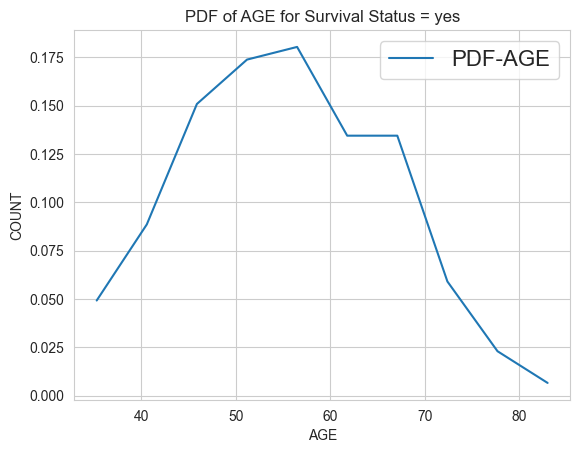

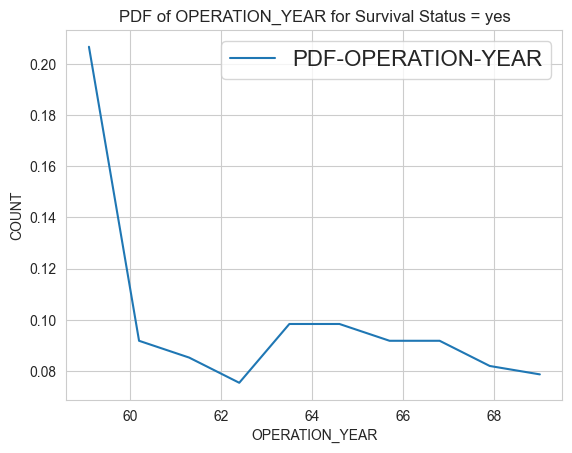

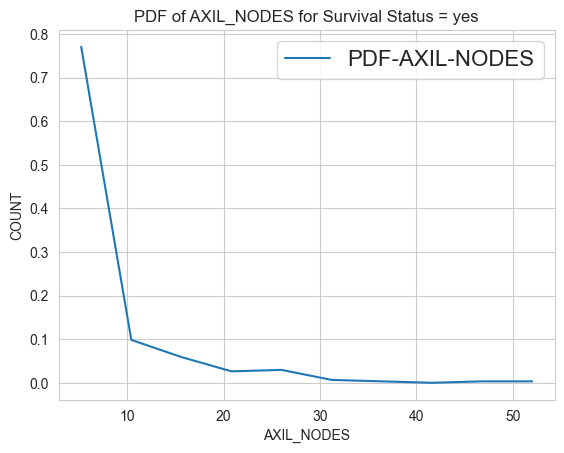

In [131]:
counts, bin_edges = np.histogram(haberman["age"], bins=10, density=True)
pdf = counts / sum(counts)
plt.plot(bin_edges[1:], pdf)
plt.ylabel("COUNT")
plt.xlabel("AGE")
plt.title("PDF of AGE for Survival Status = yes")
plt.legend(["PDF-AGE"], prop={"size": 16})
plt.show()

counts, bin_edges = np.histogram(haberman["operation_year"], bins=10, density=True)
pdf = counts / sum(counts)
plt.plot(bin_edges[1:], pdf)
plt.ylabel("COUNT")
plt.xlabel("OPERATION_YEAR")
plt.title("PDF of OPERATION_YEAR for Survival Status = yes")
plt.legend(["PDF-OPERATION-YEAR"], prop={"size": 16})
plt.show()

counts, bin_edges = np.histogram(haberman["axil_nodes"], bins=10, density=True)
pdf = counts / sum(counts)
plt.plot(bin_edges[1:], pdf)
plt.ylabel("COUNT")
plt.xlabel("AXIL_NODES")
plt.title("PDF of AXIL_NODES for Survival Status = yes")
plt.legend(["PDF-AXIL-NODES"], prop={"size": 16})
plt.show()

* Observation

1. The probability distribution function (PDF) for the people who survived and those who died different in case of axil_nodes. Hence, axil_nodes is the most important feature to predict the survival_status after $5$ years.

2. The survival rate is extremely high for pariens having less than $3$ axil_nodes.

### _CDF (Cumulative Distribution Function)_

Cumulative distribution function (CDF) of a real-valued random variable x, or distribution function of x, evaluated at x, is the x will take a value less than or equal to x.

* The advantage of the cumulative distribution function is that it can be defined for any kind of random variable (discrete, continuous and mixed).
* CDFs of a random variable is defined for all real numbers.
* CDFs is defined for all real vlues x, sometimes implicitly rather than explicitly.
* This is a standard technique in statistical analysis, and this new function that we obtain by integrating the entire provavility density function is called the cumulative distribution function

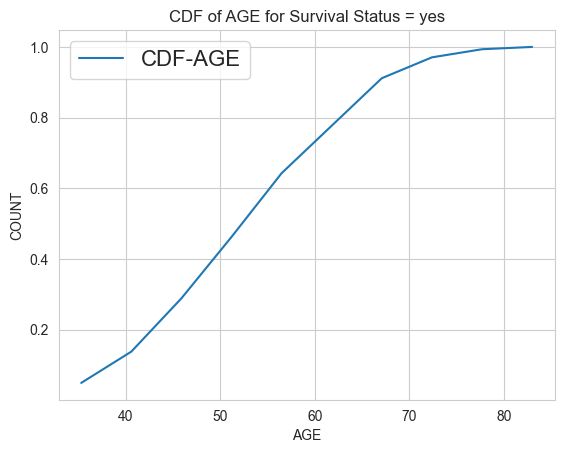

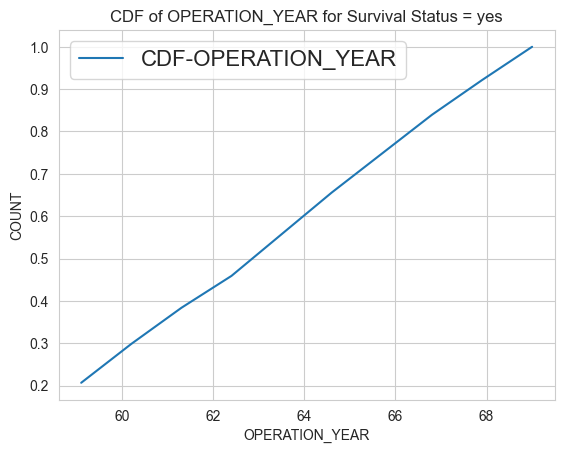

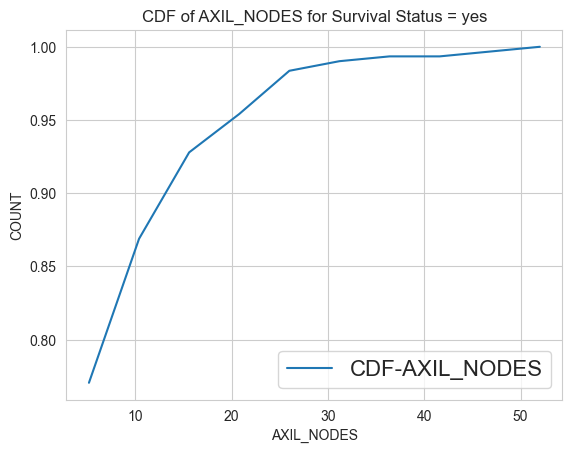

In [132]:
df_sur = haberman.loc[haberman["survival_status"] == 1]
counts, bin_edges = np.histogram(haberman["age"], bins=10, density=True)
cdf = counts / sum(counts)
cdf = np.cumsum(cdf)
plt.plot(bin_edges[1:], cdf)
plt.ylabel("COUNT")
plt.xlabel("AGE")
plt.title("CDF of AGE for Survival Status = yes")
plt.legend(["CDF-AGE"], prop={"size": 16})
plt.show()

df_sur = haberman.loc[haberman["survival_status"] == 2]
counts, bin_edges = np.histogram(haberman["operation_year"], bins=10, density=True)
cdf = counts / sum(counts)
cdf = np.cumsum(cdf)
plt.plot(bin_edges[1:], cdf)
plt.ylabel("COUNT")
plt.xlabel("OPERATION_YEAR")
plt.title("CDF of OPERATION_YEAR for Survival Status = yes")
plt.legend(["CDF-OPERATION_YEAR"], prop={"size": 16})
plt.show()

df_sur = haberman.loc[haberman["survival_status"] == 3]
counts, bin_edges = np.histogram(haberman["axil_nodes"], bins=10, density=True)
cdf = counts / sum(counts)
cdf = np.cumsum(cdf)
plt.plot(bin_edges[1:], cdf)
plt.ylabel("COUNT")
plt.xlabel("AXIL_NODES")
plt.title("CDF of AXIL_NODES for Survival Status = yes")
plt.legend(["CDF-AXIL_NODES"], prop={"size": 16})
plt.show()

* Observation

1. From the pdf and cdf we can say that $100%$ of the $1$ had less than $40$ axil_nodes and $4$% have less than $10$ axil_nodes.

### _Box Plot_

Box plot shows the distribution of quantitative data in a way that facilitates comparisons between variables or across levels of a categorical variable. The box shows the quartiles of the dataset while the whiskers extend to show the rest of the distribution, except for points that are determined to be "outliers" using a method that is a function of the inter-quartile range.

* Efficient way for presenting data, especially when it comes to comparing multiple groups thereof.
* We can mark-off the five number summary of a data set (minimum, $25th$ percentile, median,$75th$ percentile,, maximum).
* The box contains $50$% of the data, and the upper edge of the box represents the $75th$ percentile, while the lower edge is the $25th$ percentile.
* The median is represented by a line drawn in the middle of the box.
* The interquartile range (IQR) is the difference between the upper quartile and the lower quartile.
* Useful because it is less influenced by extreme values as it limits the range to the middle $50$% of the values.

**History of Box plot :-** The range-bar method was first introduced by Mary Eleanor Spear in her book `Charting Statistics` in $1952$ and again in her book `Practical Charting Techniques` in $1969$. The box-and-whisker plot was first introduced in $1970$ by John Tukey, who later published on the subject in his book `Exploratory Data Analysis` in $1977$.

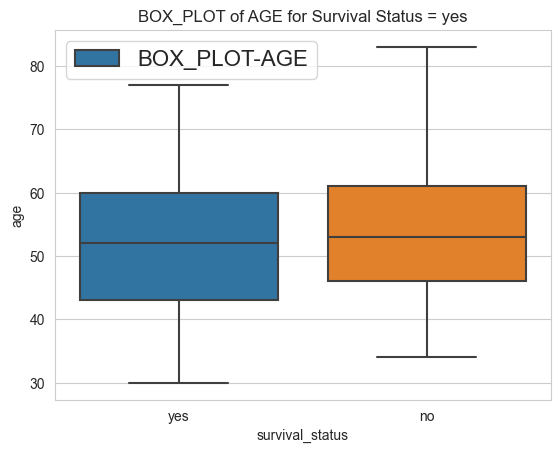

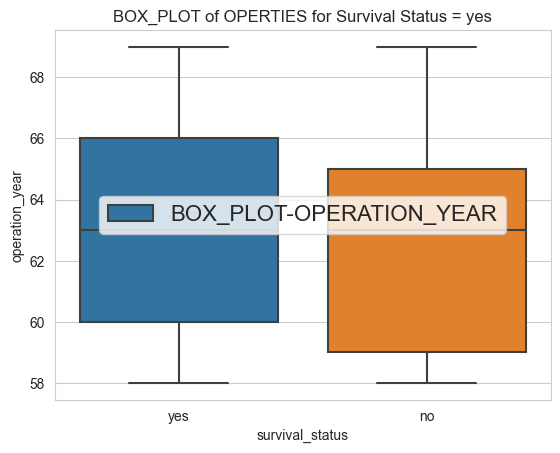

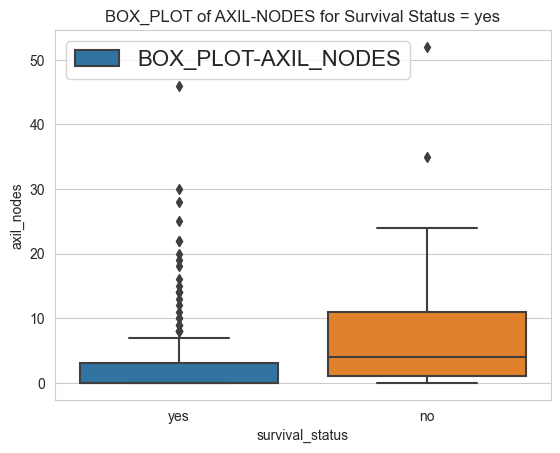

In [133]:
sbn.boxplot(x="survival_status", y="age", data=haberman)
plt.ylabel("age")
plt.xlabel("survival_status")
plt.title("BOX_PLOT of AGE for Survival Status = yes")
plt.legend(["BOX_PLOT-AGE"], prop={"size": 16})
plt.show()

sbn.boxplot(x="survival_status", y="operation_year", data=haberman)
plt.ylabel("operation_year")
plt.xlabel("survival_status")
plt.title("BOX_PLOT of OPERTIES for Survival Status = yes")
plt.legend(["BOX_PLOT-OPERATION_YEAR"], prop={"size": 16})
plt.show()

sbn.boxplot(x="survival_status", y="axil_nodes", data=haberman)
plt.ylabel("axil_nodes")
plt.xlabel("survival_status")
plt.title("BOX_PLOT of AXIL-NODES for Survival Status = yes")
plt.legend(["BOX_PLOT-AXIL_NODES"], prop={"size": 16})
plt.show()

* Observation

1. Boxplot of $1$ had only $75th$ percentile value at axil_nodes is $2$ and the $25th$ and $50th$ percentiles are ovelapped.

2. Boxplot of $2$ had only $25th$ percentile value at axil_nodes is $1,50th$ percentile value at axil_nodes is $3$ and $75th$ percentile value at axil_nodes is $11$.

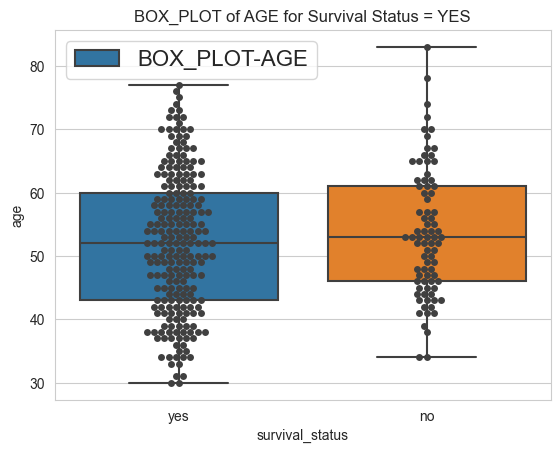

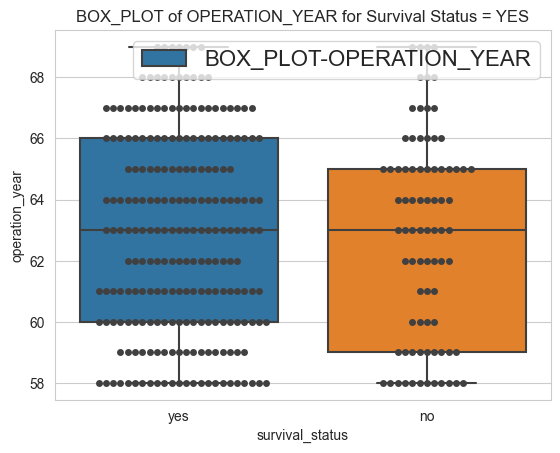

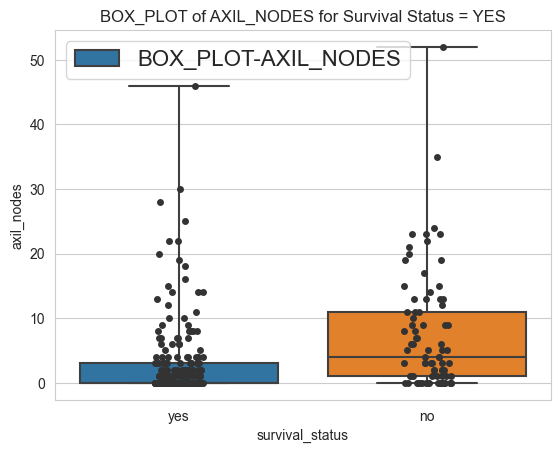

In [134]:
ax = sbn.boxplot(x="survival_status", y="age", data=haberman)
ax = sbn.swarmplot(x="survival_status", y="age", data=haberman, color=".25")
plt.ylabel("age")
plt.xlabel("survival_status")
plt.title("BOX_PLOT of AGE for Survival Status = YES")
plt.legend(["BOX_PLOT-AGE"], prop={"size": 16})
plt.show()

ax = sbn.boxplot(x="survival_status", y="operation_year", data=haberman)
ax = sbn.swarmplot(x="survival_status", y="operation_year", data=haberman, color=".25")
plt.ylabel("operation_year")
plt.xlabel("survival_status")
plt.title("BOX_PLOT of OPERATION_YEAR for Survival Status = YES")
plt.legend(["BOX_PLOT-OPERATION_YEAR"], prop={"size": 16})
plt.show()

ax = sbn.boxplot(x="survival_status", y="axil_nodes", data=haberman, whis=np.inf)
ax = sbn.stripplot(x="survival_status", y="axil_nodes", data=haberman, color=".2")
plt.ylabel("axil_nodes")
plt.xlabel("survival_status")
plt.title("BOX_PLOT of AXIL_NODES for Survival Status = YES")
plt.legend(["BOX_PLOT-AXIL_NODES"], prop={"size": 16})
plt.show()

### _Violin Plot_

A violin plot is a statistical graphic for comparing probability distributions. It is similar to a box plot, with the addition of a rotated kernel density plot on each side.

* Violin plot is a method of plotting numeric data.
* It's a combination of a Box plot and a Density plot.
* The thick black bar in the center represents the interquartile range, the thin black line extended from it represents the $95$% confidence intervals, and the white dot is the median.

**History of Violin Plot :-** The violin plot was proposed in $1997$ by Jerry L. Hintze and Ray D. Nelson as a way to display even more information than box plots, which were created by John Tukey in $1977$. The name comes from the plot's alleged resemblance to a violin.

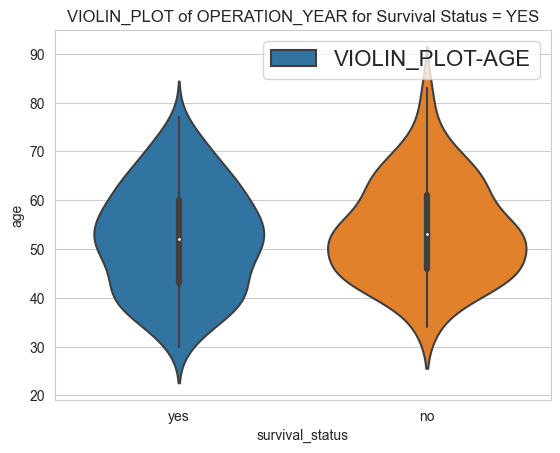

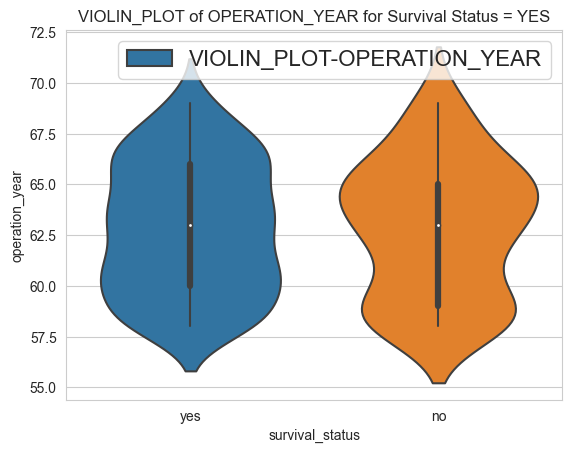

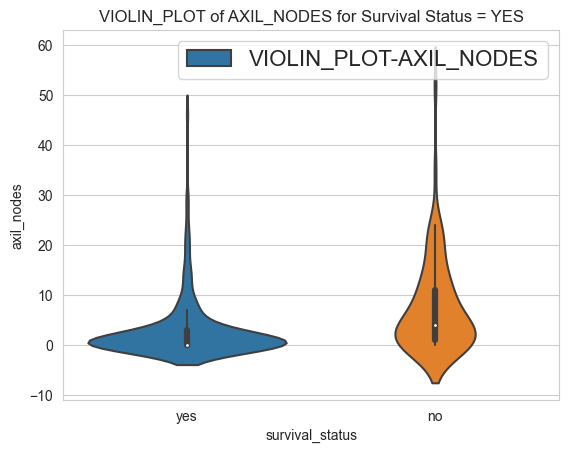

In [135]:
sbn.violinplot(x="survival_status", y="age", data=haberman)
plt.ylabel("age")
plt.xlabel("survival_status")
plt.title("VIOLIN_PLOT of OPERATION_YEAR for Survival Status = YES")
plt.legend(["VIOLIN_PLOT-AGE"], prop={"size": 16})
plt.show()

sbn.violinplot(x="survival_status", y="operation_year", data=haberman)
plt.ylabel("operation_year")
plt.xlabel("survival_status")
plt.title("VIOLIN_PLOT of OPERATION_YEAR for Survival Status = YES")
plt.legend(["VIOLIN_PLOT-OPERATION_YEAR"], prop={"size": 16})
plt.show()

sbn.violinplot(x="survival_status", y="axil_nodes", data=haberman)
plt.ylabel("axil_nodes")
plt.xlabel("survival_status")
plt.title("VIOLIN_PLOT of AXIL_NODES for Survival Status = YES")
plt.legend(["VIOLIN_PLOT-AXIL_NODES"], prop={"size": 16})
plt.show()

* Observation

1. $50th$ percent of survivors have $0$ positive nodes, $75th$ percent of survivors have less than $3$ positive axillary nodes.

2. $25th$ percent of dead have $1$ positive axillary node, $50th$ percent of dead have positive axillary nodes below $4$.

3. $75th$ percent of dead have positive nodes below $11$.

4. The number of survival_status of the survivors is highly densed from $0$ to $5$.

5. Almost $80$% of the patients have less then or equal to $5$ survival_status more than $5$ years.

6. From box plots and violin plots, we can say that more no of patients who are dead have age between $46-62$ or $59-65$ and the patients who survived have age between $42-60$ or $60-66$.

## _Bivariate analysis_

Bivariate analysis is one of the simplest forms of quantitative (statistical) analysis. It involves the analysis of two variables (often denoted as X, Y), for the purpose of determining the empirical relationship between them. It means the analysis of bivariate data. It is one of the simplest forms of statistical analysis, used to find out if ther is a relationship betweeen two sets of balues. It usually involves the variables X and Y.

### _Scatter Plot_

Scatter plot is a type of plot or mathematical diagram using Cartesian coordinates to display values for typically two variables for a set of data. If the points are coded (color/shape/size), one additional variable can be displayed. The data are displayed as a collection of points, each having the value of one variable determining the position on the horizontal axis and the value of the other variable determining the position on the vertical axis

* Visualizes the bivariate relationships among several pairs of variavles.

* The graph looks like a bunch of dots, but some of the graphs are a general shape or move in a general direction.

* To test the linear relationship between continuous variables scatter plot is a good option. We can find out how one variable is changing w.r.t another variable.

#### _1D Scatter plot_

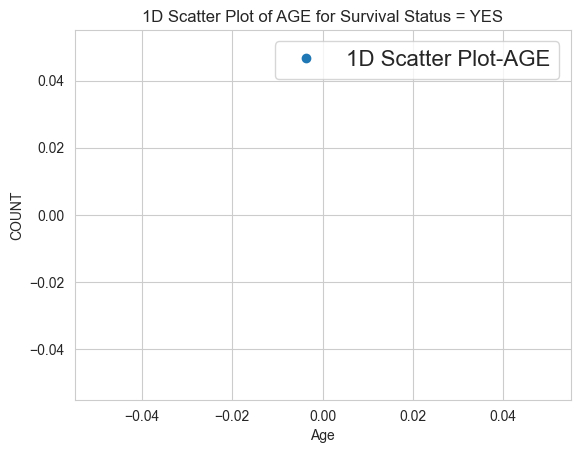

In [136]:
X = df.loc[haberman["survival_status"] == 1]
Y = df.loc[haberman["survival_status"] == 2]
plt.plot(X["age"], np.zeros_like(X["age"]), "o", label="survival_status\n" "1")
plt.plot(X["age"], np.zeros_like(X["age"]), "o", label="survival_status\n" "2")
plt.ylabel("COUNT")
plt.xlabel("Age")
plt.title("1D Scatter Plot of AGE for Survival Status = YES")
plt.legend(["1D Scatter Plot-AGE"], prop={"size": 16})
plt.show()

#### _2D Scatter plot_

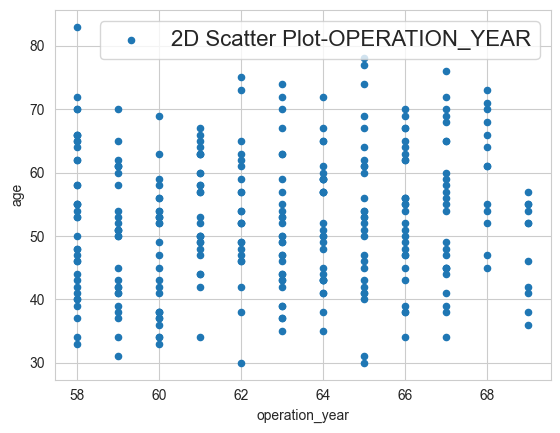

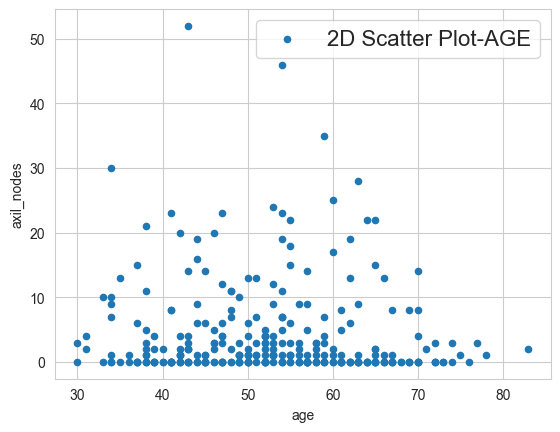

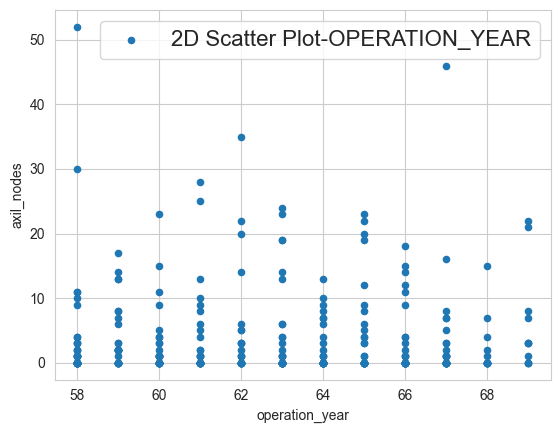

In [137]:
haberman.plot(kind="scatter", x="operation_year", y="age")
plt.ylabel("age")
plt.xlabel("operation_year")
plt.legend(["2D Scatter Plot-OPERATION_YEAR"], prop={"size": 16})
plt.show()

haberman.plot(kind="scatter", x="age", y="axil_nodes")
plt.ylabel("axil_nodes")
plt.xlabel("age")
plt.legend(["2D Scatter Plot-AGE"], prop={"size": 16})

haberman.plot(kind="scatter", x="operation_year", y="axil_nodes")
plt.ylabel("axil_nodes")
plt.xlabel("operation_year")
plt.legend(["2D Scatter Plot-OPERATION_YEAR"], prop={"size": 16})
plt.show()

#### _3D Scatter plot_

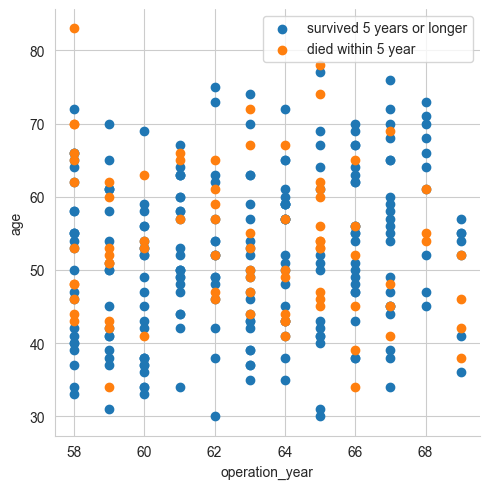

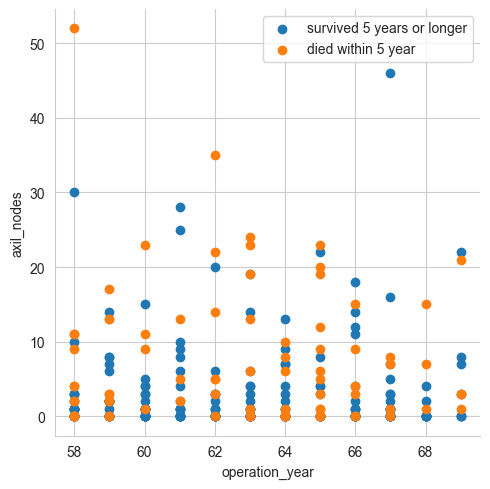

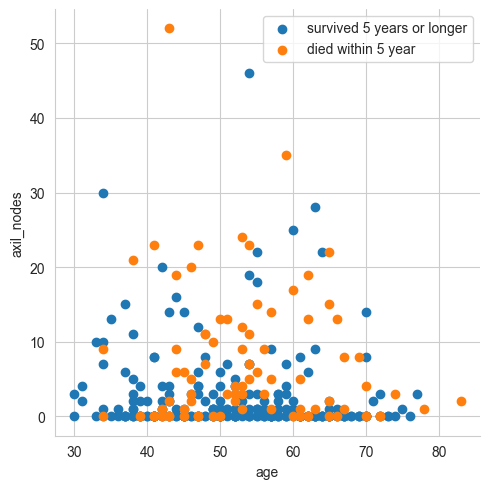

In [138]:
label = ['survived 5 years or longer','died within 5 year']
sbn.set_style("whitegrid");
sbn.FacetGrid(haberman, hue="survival_status", height=5).map(plt.scatter,"operation_year", "age")  
plt.ylabel("age")
plt.xlabel('operation_year')
plt.legend(label)
plt.show() 

label = ['survived 5 years or longer','died within 5 year']
sbn.set_style("whitegrid");
sbn.FacetGrid(haberman, hue="survival_status", height=5).map(plt.scatter,"operation_year", "axil_nodes")  
plt.ylabel("axil_nodes")
plt.xlabel('operation_year')
plt.legend(label)
plt.show() 

label = ['survived 5 years or longer','died within 5 year']
sbn.set_style("whitegrid");
sbn.FacetGrid(haberman, hue="survival_status", height=5).map(plt.scatter,"age", "axil_nodes")
plt.ylabel("axil_nodes")
plt.xlabel('age')
plt.legend(label)
plt.show()

* Observation

1. It seems most of the patients have 0 positive lymph nodes detected.
2. Here we clearly see that blue points are not seperated from orange points
3. So, by looking at this 2D scatter plot between 'Age' and 'positive_lymph_nodes' we can't make any decision regarding patient's survival.
4. Therefore, we have to check all combination/pair of features to make good classification/decision.
5. Number of Combinations of features : 3C2 = 3 (excluding class-attribute 'Survival')
6. Now, for these combination to analyse, Pair-Plot concept is used.